# Trabalho de Grupo - Análise de Séries Temporais e Previsão (ASTP) 2026
**Mestrado em Ciência de Dados (ISCTE)**

**País Temático**: Noruega (Norway)
**Variáveis Analisadas**:
1. **Share Price Index for Norway** (Índice de Ações da Noruega - Variável de Interesse)
2. **Brent Crude Oil Price** (Preço do Petróleo Brent - Commodity de Impacto)
3. **USD/NOK Exchange Rate** (Taxa de Câmbio USD/NOK - Variável Monetária)

---

## 1. Setup e Importação de Dados
Nesta secção, importamos as bibliotecas necessárias e descarregamos/carregamos a base de dados contendo as 3 séries temporais mensais da Noruega obtidas diretamente do repositório da FRED.

In [18]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os
from statsmodels.tsa.stattools import adfuller, kpss
!pip install arch
!pip install pmdarima
from arch.unitroot import PhillipsPerron
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.tsa.api import VAR
from statsmodels.tsa.vector_ar.vecm import coint_johansen
import pmdarima as pm
import torch
import torch.nn as nn
import torch.optim as optim
from sklearn.metrics import mean_squared_error, mean_absolute_error

# Carregar os dados combinados da pasta data/
# O caminho 'C:/Users/André Marques/Desktop/...' é um caminho local da sua máquina
# e não pode ser acessado diretamente pelo ambiente Google Colab.
# O arquivo 'norway_data.csv' foi carregado para '/content/'.
df = pd.read_csv('data/norway_data.csv', parse_dates=['observation_date'], index_col='observation_date')
print(f"Dados carregados com sucesso! Dimensão: {df.shape}")
df.head()

ERROR: Operation cancelled by user
Traceback (most recent call last):
  File "/usr/local/lib/python3.12/dist-packages/pip/_internal/cli/base_command.py", line 179, in exc_logging_wrapper
    status = run_func(*args)
             ^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.12/dist-packages/pip/_internal/cli/req_command.py", line 67, in wrapper
    return func(self, options, args)
           ^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.12/dist-packages/pip/_internal/commands/install.py", line 324, in run
    session = self.get_default_session(options)
              ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.12/dist-packages/pip/_internal/cli/index_command.py", line 71, in get_default_session
    self._session = self.enter_context(self._build_session(options))
                                       ^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.12/dist-packages/pip/_internal/cli/index_command.py", line 100, in _build_session
    session = 

,Share_Index,USD_NOK,Brent_Oil
observation_date,,,
1992-01-01,9.322927,6.2044,18.156522
1992-02-01,8.923073,6.3472,18.110000
1992-03-01,8.944118,6.5188,17.659091
1992-04-01,8.838893,6.4606,19.015909
1992-05-01,9.554422,6.3311,19.980952


## 2. Estatísticas Descritivas e Análise Gráfica
Vamos dividir a amostra em 90% para treino e 10% para teste, e analisar as características estatísticas do conjunto de treino.

Treino: 1992-01-01 a 2022-09-01 (369 obs)
Teste: 2022-10-01 a 2026-03-01 (42 obs)

Estatísticas Descritivas (Treino):


,count,mean,std,min,25%,50%,75%,max,skewness,kurtosis
Share_Index,369.0,66.798740,52.018538,6.734395,23.283840,60.131310,97.321190,216.426800,0.924498,0.038656
USD_NOK,369.0,7.227708,1.204146,5.054100,6.239700,6.998900,8.270000,10.419900,0.348757,-0.882198
Brent_Oil,369.0,53.006198,32.955381,10.160000,22.178571,48.906364,74.403182,133.585217,0.570522,-0.840191


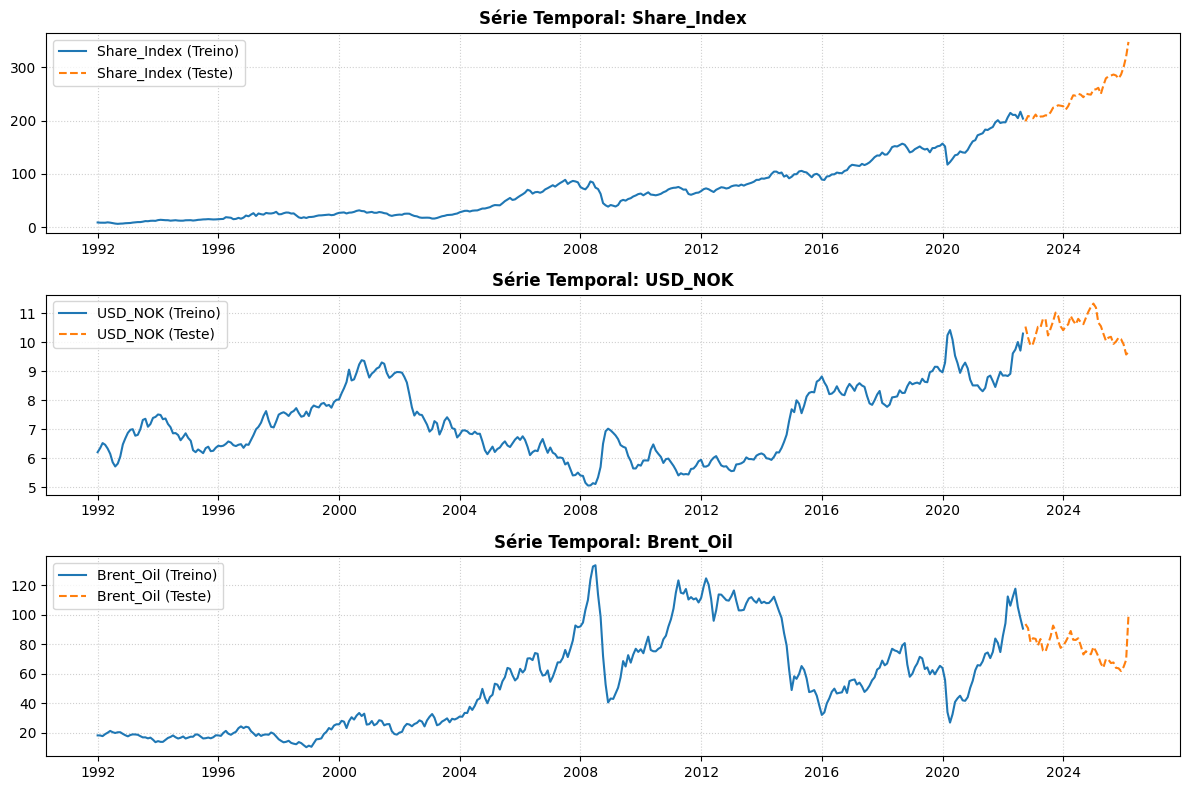

In [19]:
n_obs = len(df)
train_size = int(n_obs * 0.90)
train_df = df.iloc[:train_size]
test_df = df.iloc[train_size:]

print(f"Treino: {train_df.index.min().date()} a {train_df.index.max().date()} ({len(train_df)} obs)")
print(f"Teste: {test_df.index.min().date()} a {test_df.index.max().date()} ({len(test_df)} obs)")

# Estatísticas Descritivas
desc = train_df.describe().transpose()
desc['skewness'] = train_df.skew()
desc['kurtosis'] = train_df.kurt()
print("\nEstatísticas Descritivas (Treino):")
display(desc)

# Visualização Gráfica
plt.figure(figsize=(12, 8))
for i, col in enumerate(df.columns):
    plt.subplot(3, 1, i+1)
    plt.plot(train_df.index, train_df[col], label=f'{col} (Treino)', lw=1.5)
    plt.plot(test_df.index, test_df[col], label=f'{col} (Teste)', linestyle='--', lw=1.5)
    plt.title(f'Série Temporal: {col}', fontweight='bold')
    plt.grid(True, linestyle=':', alpha=0.6)
    plt.legend()
plt.tight_layout()
plt.show()

## 3. Testes de Estacionaridade (ADF, PP, KPSS)
A estacionaridade é testada usando 3 testes diferentes:
- **ADF (Augmented Dickey-Fuller)**: H0 = Série tem raiz unitária (não-estacionária).
- **PP (Phillips-Perron)**: H0 = Série tem raiz unitária (não-estacionária).
- **KPSS**: H0 = Série é estacionária (p < 0.05 rejeita H0).

Se as séries forem não-estacionárias em nível, aplicamos a primeira diferença do logaritmo natural.

In [20]:
def check_unit_roots(series):
    adf = adfuller(series.dropna(), autolag='AIC', regression='ct')
    pp = PhillipsPerron(series.dropna(), trend='ct')
    kps = kpss(series.dropna(), regression='ct')
    return {
        'ADF p-val': adf[1],
        'PP p-val': pp.pvalue,
        'KPSS Stat': kps[0], # KPSS p-value aproximado
        'KPSS p-val': kps[1]
    }

print("=== TESTES EM NÍVEL ===")
for col in train_df.columns:
    res = check_unit_roots(train_df[col])
    print(f"{col:12} | ADF p={res['ADF p-val']:.4f} | PP p={res['PP p-val']:.4f} | KPSS stat={res['KPSS Stat']:.4f} (p={res['KPSS p-val']:.4f})")

# Aplicar primeira diferença dos logs
train_diff = np.log(train_df).diff().dropna()
print("\n=== TESTES EM 1ª DIFERENÇA DO LOG ===")
for col in train_diff.columns:
    res = check_unit_roots(train_diff[col])
    print(f"{col:12} (diff) | ADF p={res['ADF p-val']:.4f} | PP p={res['PP p-val']:.4f} | KPSS stat={res['KPSS Stat']:.4f} (p={res['KPSS p-val']:.4f})")

=== TESTES EM NÍVEL ===
Share_Index  | ADF p=0.8481 | PP p=0.8815 | KPSS stat=0.4924 (p=0.0100)
USD_NOK      | ADF p=0.9060 | PP p=0.8749 | KPSS stat=0.4298 (p=0.0100)
Brent_Oil    | ADF p=0.1350 | PP p=0.3787 | KPSS stat=0.3471 (p=0.0100)

=== TESTES EM 1ª DIFERENÇA DO LOG ===
Share_Index  (diff) | ADF p=0.0000 | PP p=0.0000 | KPSS stat=0.0291 (p=0.1000)
USD_NOK      (diff) | ADF p=0.0000 | PP p=0.0000 | KPSS stat=0.0855 (p=0.1000)
Brent_Oil    (diff) | ADF p=0.0000 | PP p=0.0000 | KPSS stat=0.0451 (p=0.1000)


/tmp/ipykernel_4426/3024094850.py:4: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is smaller than the p-value returned.

  kps = kpss(series.dropna(), regression='ct')
/tmp/ipykernel_4426/3024094850.py:4: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is smaller than the p-value returned.

  kps = kpss(series.dropna(), regression='ct')
/tmp/ipykernel_4426/3024094850.py:4: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is smaller than the p-value returned.

  kps = kpss(series.dropna(), regression='ct')
/tmp/ipykernel_4426/3024094850.py:4: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is greater than the p-value returned.

  kps = kpss(series.dropna(), regression='c

## 4. Teste de Cointegração de Johansen
Antes de construir um modelo multivariado, testamos a existência de cointegração (relação de longo prazo estável em nível) entre as séries para decidir se usamos um modelo **VAR** ou **VECM**.

In [21]:
train_log = np.log(train_df)
coint_res = coint_johansen(train_log, det_order=0, k_ar_diff=1)
print("Estatísticas de Traço (Johansen):")
for i in range(3):
    print(f"Rank r <= {i}: Trace Stat = {coint_res.lr1[i]:.4f} | Val Crítico 95% = {coint_res.cvt[i, 1]:.4f}")
print("\nConclusão: Como as estatísticas são inferiores aos valores críticos, não há cointegração (r = 0).")
print("Portanto, modelamos em primeiras diferenças usando um VAR (Vector Autoregression).")

Estatísticas de Traço (Johansen):
Rank r <= 0: Trace Stat = 15.2973 | Val Crítico 95% = 29.7961
Rank r <= 1: Trace Stat = 4.9188 | Val Crítico 95% = 15.4943
Rank r <= 2: Trace Stat = 0.6310 | Val Crítico 95% = 3.8415

Conclusão: Como as estatísticas são inferiores aos valores críticos, não há cointegração (r = 0).
Portanto, modelamos em primeiras diferenças usando um VAR (Vector Autoregression).


## 5. Modelo 1: SARIMAX (Univariado com Exógena)
Ajustamos um modelo SARIMAX para a variável de interesse `Share_Index`, usando `Brent_Oil` (log) como variável exógena, e determinando a ordem automática via Critério de Informação de Akaike (AIC).

In [22]:
exog_train = train_log[['Brent_Oil']]
exog_test = np.log(test_df[['Brent_Oil']])

print("A otimizar ordem SARIMAX com auto_arima...")
sarimax_auto = pm.auto_arima(
    train_log['Share_Index'],
    X=exog_train,
    d=1, seasonal=True, m=12, stepwise=True,
    suppress_warnings=True, error_action="ignore"
)
print(f"Melhor Modelo: SARIMAX{sarimax_auto.order}x{sarimax_auto.seasonal_order}")

sarimax_model = SARIMAX(
    train_log['Share_Index'], exog=exog_train,
    order=sarimax_auto.order, seasonal_order=sarimax_auto.seasonal_order,
    enforce_stationarity=False, enforce_invertibility=False
)
sarimax_results = sarimax_model.fit(disp=False)
print(sarimax_results.summary())

# Previsão out-of-sample
sarimax_pred_log = sarimax_results.predict(start=test_df.index[0], end=test_df.index[-1], exog=exog_test)
sarimax_pred = np.exp(sarimax_pred_log)

A otimizar ordem SARIMAX com auto_arima...
Melhor Modelo: SARIMAX(1, 1, 1)x(0, 0, 0, 12)


/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)


                               SARIMAX Results                                
Dep. Variable:            Share_Index   No. Observations:                  369
Model:               SARIMAX(1, 1, 1)   Log Likelihood                 564.319
Date:                Wed, 27 May 2026   AIC                          -1120.637
Time:                        14:52:20   BIC                          -1105.027
Sample:                    01-01-1992   HQIC                         -1114.434
                         - 09-01-2022                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
Brent_Oil      0.2898      0.025     11.662      0.000       0.241       0.339
ar.L1         -0.6494      0.072     -9.074      0.000      -0.790      -0.509
ma.L1          0.8120      0.063     12.907      0.0

## 6. Modelo 2: VAR (Vector Autoregression)
O modelo VAR capta a dinâmica multivariada e de feedback bidirecional entre as variações do índice de ações, petróleo Brent e taxa de câmbio.

In [23]:
var_model = VAR(train_diff)
best_lag = var_model.select_order(maxlags=12).aic
print(f"Melhor lag (AIC): {best_lag}")
var_results = var_model.fit(best_lag if best_lag > 0 else 1)
print(var_results.summary())

# Previsão recursiva out-of-sample
var_inputs = train_diff.values[-best_lag:]
var_preds_diff = var_results.forecast(var_inputs, steps=len(test_df))

# Reconstrução de níveis
var_pred = []
last_val_log = train_log['Share_Index'].iloc[-1]
for d_pred in var_preds_diff[:, 0]:
    next_val_log = last_val_log + d_pred
    var_pred.append(np.exp(next_val_log))
    last_val_log = next_val_log
var_pred = pd.Series(var_pred, index=test_df.index)

Melhor lag (AIC): 2
  Summary of Regression Results   
Model:                         VAR
Method:                        OLS
Date:           Wed, 27, May, 2026
Time:                     14:52:20
--------------------------------------------------------------------
No. of Equations:         3.00000    BIC:                   -18.2142
Nobs:                     366.000    HQIC:                  -18.3492
Log likelihood:           1837.19    FPE:                9.82682e-09
AIC:                     -18.4382    Det(Omega_mle):     9.28388e-09
--------------------------------------------------------------------
Results for equation Share_Index
                    coefficient       std. error           t-stat            prob
---------------------------------------------------------------------------------
const                  0.007270         0.003110            2.337           0.019
L1.Share_Index         0.130477         0.058356            2.236           0.025
L1.USD_NOK            -0.03634

/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)


## 7. Modelo 3: Redes Neuronais Recorrentes (LSTM)
Construímos uma rede LSTM em PyTorch. O modelo usa 3 lags das 3 variáveis log-diferenciadas para prever dinamicamente o próximo log-retorno do índice de ações norueguês.

In [24]:
full_diff = np.log(df).diff().dropna()
train_diff_val = full_diff.iloc[:train_size-1].values
lookback = 3

def create_dataset(data, lookback):
    X, y = [], []
    for i in range(len(data) - lookback):
        X.append(data[i:i+lookback])
        y.append(data[i+lookback, 0])
    return np.array(X), np.array(y)

X_train, y_train = create_dataset(train_diff_val, lookback)
X_train_t = torch.FloatTensor(X_train)
y_train_t = torch.FloatTensor(y_train).unsqueeze(1)

# Arquitetura da Rede LSTM
class LSTMForecaster(nn.Module):
    def __init__(self, input_dim, hidden_dim, num_layers=1):
        super(LSTMForecaster, self).__init__()
        self.lstm = nn.LSTM(input_dim, hidden_dim, num_layers, batch_first=True)
        self.fc = nn.Linear(hidden_dim, 1)
    def forward(self, x):
        out, _ = self.lstm(x)
        return self.fc(out[:, -1, :])

model_lstm = LSTMForecaster(input_dim=3, hidden_dim=8)
criterion = nn.MSELoss()
optimizer = optim.Adam(model_lstm.parameters(), lr=0.01)

# Treino
model_lstm.train()
for epoch in range(150):
    optimizer.zero_grad()
    out = model_lstm(X_train_t)
    loss = criterion(out, y_train_t)
    loss.backward()
    optimizer.step()
print(f"Treino terminado! Loss final: {loss.item():.6f}")

# Previsão no conjunto de teste
model_lstm.eval()
test_diff_val = full_diff.iloc[train_size-1-lookback:].values
X_test, _ = create_dataset(test_diff_val, lookback)
X_test_t = torch.FloatTensor(X_test)

with torch.no_grad():
    lstm_preds_diff = model_lstm(X_test_t).numpy().flatten()

# Reconstruir em níveis
lstm_pred = []
last_val_log = train_log['Share_Index'].iloc[-1]
for d_pred in lstm_preds_diff[:len(test_df)]:
    next_val_log = last_val_log + d_pred
    lstm_pred.append(np.exp(next_val_log))
    last_val_log = next_val_log
lstm_pred = pd.Series(lstm_pred, index=test_df.index)

Treino terminado! Loss final: 0.003303


## 8. Avaliação Out-of-Sample e Previsão Futura (10 Meses)
Calculamos as métricas de avaliação (RMSE, MAE, MAPE) para os três modelos e geramos gráficos de comparação das previsões out-of-sample e previsões futuras para o ano de 2026.

=== COMPARAÇÃO DE DESEMPENHO NO TESTE ===
SARIMAX    | RMSE = 65.5142 | MAE = 53.9044 | MAPE = 20.35%
VAR        | RMSE = 12.9974 | MAE = 7.8856 | MAPE = 2.94%
LSTM       | RMSE = 11.8374 | MAE = 7.1413 | MAPE = 2.69%


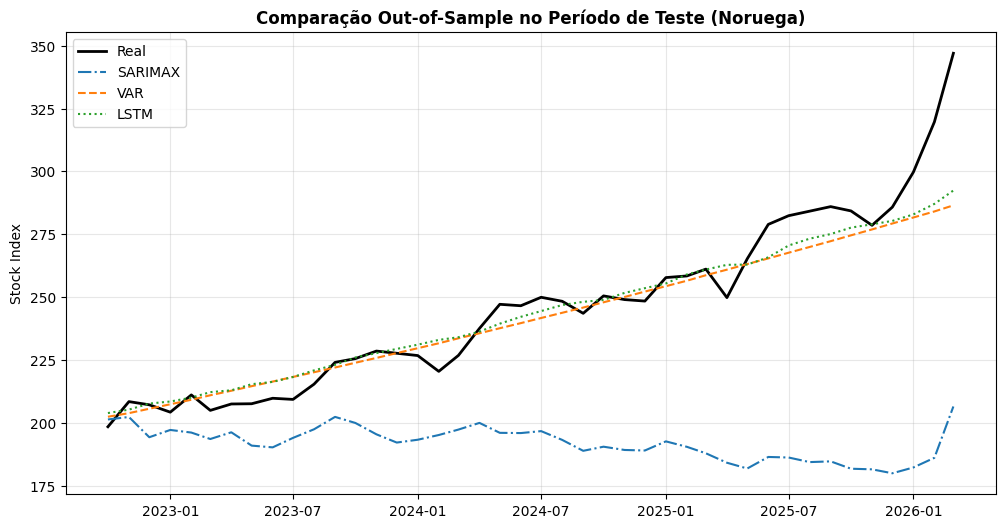

In [25]:
def eval_metrics(y_true, y_pred, name):
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    mae = mean_absolute_error(y_true, y_pred)
    mape = np.mean(np.abs((y_true - y_pred) / y_true)) * 100
    print(f"{name:10} | RMSE = {rmse:.4f} | MAE = {mae:.4f} | MAPE = {mape:.2f}%")
    return {'Model': name, 'RMSE': rmse, 'MAE': mae, 'MAPE': mape}

print("=== COMPARAÇÃO DE DESEMPENHO NO TESTE ===")
m1 = eval_metrics(test_df['Share_Index'], sarimax_pred, 'SARIMAX')
m2 = eval_metrics(test_df['Share_Index'], var_pred, 'VAR')
m3 = eval_metrics(test_df['Share_Index'], lstm_pred, 'LSTM')

# Visualização dos resultados de teste
plt.figure(figsize=(12, 6))
plt.plot(test_df.index, test_df['Share_Index'], label='Real', color='black', lw=2)
plt.plot(test_df.index, sarimax_pred, label='SARIMAX', linestyle='-.')
plt.plot(test_df.index, var_pred, label='VAR', linestyle='--')
plt.plot(test_df.index, lstm_pred, label='LSTM', linestyle=':')
plt.title('Comparação Out-of-Sample no Período de Teste (Noruega)', fontweight='bold')
plt.ylabel('Stock Index')
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()